### Load and Compute

In [30]:
import numpy as np
import pandas as pd
import os
from scipy.integrate import trapz
import utils.segment_isc_utils 

# --- CONFIGURATION ---
DATA_DIR = "../data/02_processed_combined_data"
CONDITIONS_FILE = "../data/sub_conditions.csv"
OUTPUT_DIR = "h3_hysteresis_results"

if not os.path.exists(OUTPUT_DIR): os.makedirs(OUTPUT_DIR)

# Constants
FS = 20
WINDOW_SECONDS = 15
STEP_SECONDS = 1
WIN_SIZE = int(WINDOW_SECONDS * FS)
STEP_SIZE = int(STEP_SECONDS * FS)
BRANCH_POINT = 205
TRANSITION_END = BRANCH_POINT + WINDOW_SECONDS # 220s

# Segments (Needed for max time calculation)
SEGMENTS_PC = {1: (9, 54), 2: (55, 205), 3: (205, 243), 4: (243, 278), 5: (279, 319)}

signals = ['Gaze_X', 'Gaze_Y', 'Pupil_Mean', 'Heart_Rate', 'GSR']
pc_subs  = utils.segment_isc_utils.get_subjects_by_condition(CONDITIONS_FILE, 'PC')
pcm_subs = utils.segment_isc_utils.get_subjects_by_condition(CONDITIONS_FILE, 'PCM')

# --- FUNC 1: CAUSAL SLIDING WINDOW ---
def sliding_window_group_isc(df_pc, df_pcm, win_size, step_size, n_boot=200):
    n_samples = min(df_pc.shape[0], df_pcm.shape[0])
    # Limit to relevant movie length
    max_time = SEGMENTS_PC[5][1] * FS + (10 * FS)
    if n_samples > max_time: n_samples = int(max_time)
    
    n_pc, n_pcm = df_pc.shape[1], df_pcm.shape[1]
    results = []

    # Right-Aligned (Causal) Loop
    for start_idx in range(0, n_samples - win_size, step_size):
        end_idx = start_idx + win_size
        time_sec = end_idx / FS
        
        # Data Slices
        w_pc = df_pc.iloc[start_idx:end_idx, :].values
        w_pcm = df_pcm.iloc[start_idx:end_idx, :].values
        
        # Bootstrap
        boot_rs = []
        for _ in range(n_boot):
            i_pc = np.random.choice(n_pc, n_pc, replace=True)
            i_pcm = np.random.choice(n_pcm, n_pcm, replace=True)
            # Correlation of means
            r = np.corrcoef(w_pc[:, i_pc].mean(1), w_pcm[:, i_pcm].mean(1))[0,1]
            boot_rs.append(r)
        
        # Fisher Mean
        z_vals = np.arctanh(np.clip(boot_rs, -0.999, 0.999))
        mean_r = np.tanh(np.mean(z_vals))
        results.append({'Time_Sec': time_sec, 'Mean_r': mean_r})
        
    return pd.DataFrame(results)

# --- FUNC 2: DECAY QUANTIFICATION ---
def quantify_decay(df_timecourse):
    stats = []
    for sig in df_timecourse['Signal'].unique():
        sub = df_timecourse[df_timecourse['Signal'] == sig].sort_values('Time_Sec')
        
        # 1. Baseline (Pre-Branch)
        base_mask = (sub['Time_Sec'] >= (BRANCH_POINT - 15)) & (sub['Time_Sec'] <= BRANCH_POINT)
        baseline_r = sub.loc[base_mask, 'Mean_r'].mean()
        
        # 2. Decay Zone (205-220s)
        decay = sub[(sub['Time_Sec'] > BRANCH_POINT) & (sub['Time_Sec'] <= TRANSITION_END)]
        
        if decay.empty: continue
        
        # Metric A: Half-Life
        target = baseline_r * 0.5
        below = decay[decay['Mean_r'] < target]
        t_half = below['Time_Sec'].iloc[0] - BRANCH_POINT if not below.empty else WINDOW_SECONDS
        
        # Metric B: Persistence (Normalized AUC)
        auc = trapz(decay['Mean_r'], decay['Time_Sec'])
        max_area = baseline_r * (decay['Time_Sec'].iloc[-1] - decay['Time_Sec'].iloc[0])
        norm_auc = auc / max_area if max_area > 0 else 0
        
        stats.append({
            'Signal': sig, 'Baseline_r': baseline_r,
            'Half_Life': t_half, 'Persistence_Score': norm_auc
        })
    return pd.DataFrame(stats)

# --- MAIN LOOP ---
print("Running Sliding Window Analysis...")
timecourse_results = []

for signal in signals:
    print(f"  Processing {signal}...")
    try:
        d_pc = utils.segment_isc_utils.load_physio_data(DATA_DIR, pc_subs, signal)
        d_pcm = utils.segment_isc_utils.load_physio_data(DATA_DIR, pcm_subs, signal)
        
        # Run Sliding Window
        df_res = sliding_window_group_isc(d_pc, d_pcm, WIN_SIZE, STEP_SIZE, n_boot=200)
        df_res['Signal'] = signal
        timecourse_results.append(df_res)
    except Exception as e:
        print(f"    Error: {e}")

# Save Timecourses
df_final = pd.concat(timecourse_results, ignore_index=True)
df_final.to_csv(os.path.join(OUTPUT_DIR, "hysteresis_timecourses.csv"), index=False)

# Calculate and Save Metrics
print("Calculating Decay Metrics...")
df_metrics = quantify_decay(df_final)
df_metrics.to_csv(os.path.join(OUTPUT_DIR, "hysteresis_metrics.csv"), index=False)

print("Done.")

Running Sliding Window Analysis...
  Processing Gaze_X...
  Processing Gaze_Y...
  Processing Pupil_Mean...
  Processing Heart_Rate...
  Processing GSR...
Calculating Decay Metrics...
Done.


### Plot 

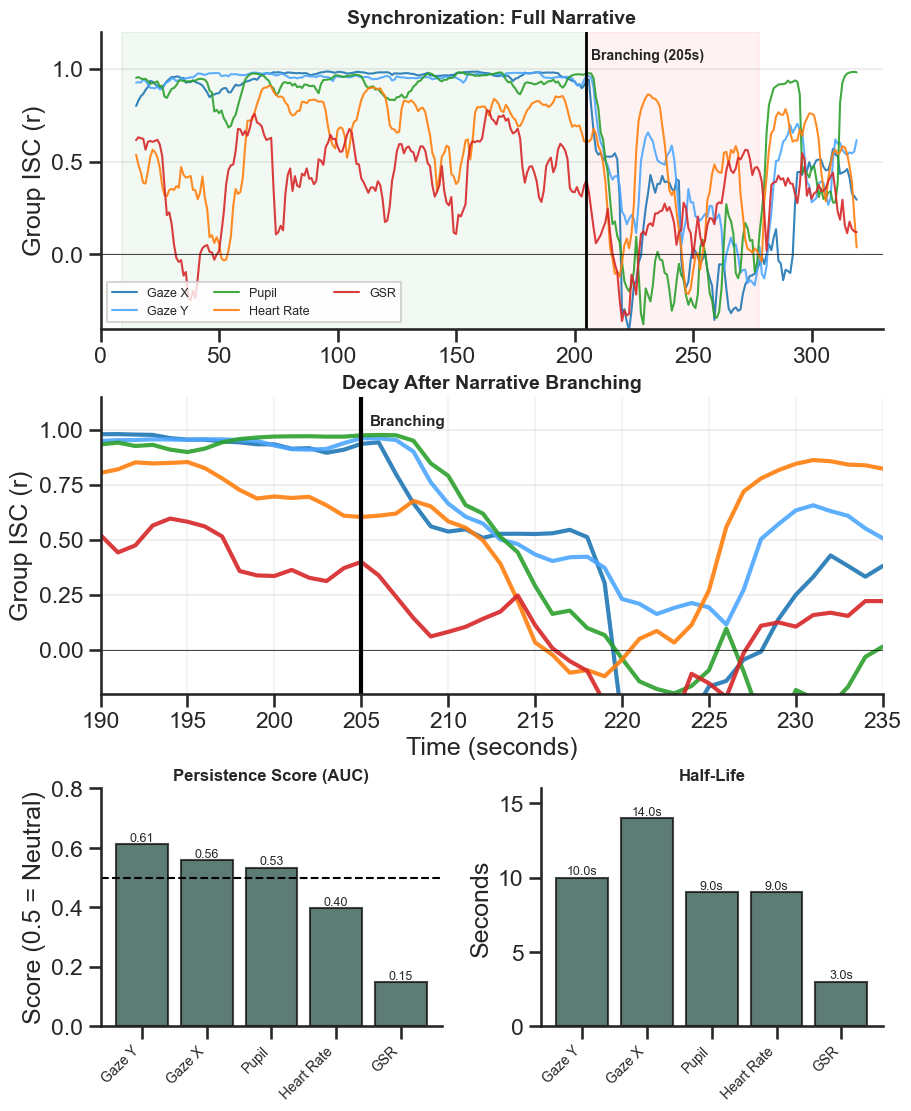

Master Figure saved to h3_hysteresis_results/Master_Hysteresis_Panel.png


In [40]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import matplotlib.gridspec as gridspec
from msuthemes import theme_msu, colors, MSU_GREEN
theme_msu()

# --- CONFIG ---
RESULTS_DIR = "h3_hysteresis_results"
TIMECOURSE_CSV = os.path.join(RESULTS_DIR, "hysteresis_timecourses.csv")
METRICS_CSV = os.path.join(RESULTS_DIR, "hysteresis_metrics.csv")
OUTPUT_PLOT = os.path.join(RESULTS_DIR, "Master_Hysteresis_Panel.png")

# Data Loading
df = pd.read_csv(TIMECOURSE_CSV)
metrics = pd.read_csv(METRICS_CSV)

# Constants
BRANCH_TIME = 205
WINDOW_SIZE = 15

# Aesthetics
signals_ordered = ['Gaze_X', 'Gaze_Y', 'Pupil_Mean', 'Heart_Rate', 'GSR']
colors = {
    'Gaze_X': '#1f77b4', 'Gaze_Y': '#4da6ff',    # Blues
    'Pupil_Mean': '#2ca02c',                     # Green
    'Heart_Rate': '#ff7f0e', 'GSR': '#d62728'    # Warm/Red
}
labels = {
    'Gaze_X': 'Gaze X', 'Gaze_Y': 'Gaze Y',
    'Pupil_Mean': 'Pupil', 'Heart_Rate': 'Heart Rate', 'GSR': 'GSR'
}

# --- PLOTTING ---
sns.set(style="ticks", context="talk")
fig = plt.figure(figsize=(9, 11), constrained_layout=True)
gs = gridspec.GridSpec(3, 2, figure=fig, height_ratios=[1, 1, 0.8])

# Define Axes
ax_macro = fig.add_subplot(gs[0, :])   # Top Row (All Cols)
ax_micro = fig.add_subplot(gs[1, :])   # Middle Row (All Cols)
ax_pers  = fig.add_subplot(gs[2, 0])   # Bottom Left
ax_half  = fig.add_subplot(gs[2, 1])   # Bottom Right

# ==========================================
# 1. MACRO VIEW (Whole Movie)
# ==========================================
for sig in signals_ordered:
    sub = df[df['Signal'] == sig]
    ax_macro.plot(sub['Time_Sec'], sub['Mean_r'], color=colors[sig], 
                  label=labels[sig], lw=1.5, alpha=0.9)

ax_macro.axvline(BRANCH_TIME, color='black', lw=2)
ax_macro.text(BRANCH_TIME+2, 1.05, "Branching (205s)", fontsize=10, fontweight='bold')
ax_macro.axvspan(9, BRANCH_TIME, color='green', alpha=0.05)
ax_macro.axvspan(BRANCH_TIME, 278, color='red', alpha=0.05)

ax_macro.set_title("Synchronization: Full Narrative", loc='center', fontweight='bold', fontsize=14)
ax_macro.set_ylim(-0.4, 1.2)
ax_macro.set_xlim(0, 330)
ax_macro.axhline(0, color='black', lw=0.5)
ax_macro.set_ylabel("Group ISC (r)")
#ax_macro.set_xticklabels([]) # Hide X labels for top plot
ax_macro.legend(loc='lower left', ncol=3, fontsize=9, frameon=True)
ax_macro.grid(axis='y', alpha=0.3)

# ==========================================
# 2. MICRO VIEW (Zoom In)
# ==========================================
x_start, x_end = 190, 235
for sig in signals_ordered:
    sub = df[df['Signal'] == sig]
    # Filter for cleaner plotting
    sub = sub[(sub['Time_Sec'] >= x_start) & (sub['Time_Sec'] <= x_end)]
    ax_micro.plot(sub['Time_Sec'], sub['Mean_r'], color=colors[sig], lw=3, alpha=0.9)

ax_micro.axvline(BRANCH_TIME, color='black', lw=3)
ax_micro.text(BRANCH_TIME+0.5, 1.02, "Branching", fontsize=11, fontweight='bold')

ax_micro.set_title("Decay After Narrative Branching", loc='center', fontweight='bold', fontsize=14)
ax_micro.set_ylim(-0.2, 1.15)
ax_micro.set_xlim(x_start, x_end)
ax_micro.axhline(0, color='black', lw=0.5)
ax_micro.set_ylabel("Group ISC (r)")
ax_micro.set_xlabel("Time (seconds)")
ax_micro.grid(axis='y', alpha=0.3)
ax_micro.grid(axis='x', alpha=0.2)

# ==========================================
# 3. METRICS (Bar Charts)
# ==========================================
# Sort metrics by Persistence Score for visual logic
metrics = metrics.sort_values('Persistence_Score', ascending=False)
bar_colors = [colors[s] for s in metrics['Signal']]
x_idx = range(len(metrics))

# --- Left: Persistence ---
bars1 = ax_pers.bar(x_idx, metrics['Persistence_Score'], color=MSU_GREEN, edgecolor='black', alpha=0.7)
ax_pers.axhline(0.5, color='black', linestyle='--', lw=1.5, label='Window Artifact')
ax_pers.set_title("Persistence Score (AUC)", loc='center', fontweight='bold', fontsize=12)
ax_pers.set_ylabel("Score (0.5 = Neutral)")
ax_pers.set_ylim(0, 0.8)
ax_pers.set_xticks(x_idx)   
ax_pers.set_xticklabels(metrics['Signal'].map(labels), rotation=45, ha='right', fontsize=10)

# Add values
for bar in bars1:
    ax_pers.text(bar.get_x() + bar.get_width()/2, bar.get_height()+0.01, 
                 f"{bar.get_height():.2f}", ha='center', fontsize=9)
#ax_pers.legend(loc='upper right', fontsize=8)

# --- Right: Half-Life ---
bars2 = ax_half.bar(x_idx, metrics['Half_Life'], color=MSU_GREEN, edgecolor='black', alpha=0.7)
ax_half.set_title("Half-Life", loc='center', fontweight='bold', fontsize=12)
ax_half.set_ylabel("Seconds")
ax_half.set_ylim(0, 16)
ax_half.set_xticks(x_idx)
ax_half.set_xticklabels(metrics['Signal'].map(labels), rotation=45, ha='right', fontsize=10)

for bar in bars2:
    ax_half.text(bar.get_x() + bar.get_width()/2, bar.get_height()+0.2, 
                 f"{bar.get_height():.1f}s", ha='center', fontsize=9)

# Final Cleanup
sns.despine()
plt.savefig(OUTPUT_PLOT, dpi=300)
plt.show()

print(f"Master Figure saved to {OUTPUT_PLOT}")

range(0, 5)

In [43]:
### OLD

### Segment-Wise ISC Analysis

In [5]:
import numpy as np
import pandas as pd
import os, sys, re
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr
from pathlib import Path
import glob

try:
    import utils.segment_isc_utils
except ImportError as e:
    print(f"\nSTILL FAILING: {e}")

### Set up Segments and Data

In [17]:
# --- CONFIGURATION ---
SEGMENTS = {
    'PC': {
        1: (9, 54),    # Premise
        2: (55, 205),  # Rising Action
        3: (205, 243), # Climax (38s)
        4: (243, 278), # Resolution (35s)
        5: (279, 319)  # Ending
    },
    'PCM': {
        1: (9, 54),
        2: (55, 205),
        3: (205, 240), # Resolution (35s) - Swapped
        4: (240, 278), # Climax (38s)     - Swapped
        5: (279, 319)
    }
}

FS = 20
WINDOW_SECONDS = 15  # 15s is standard for physiology (allows capturing slow BOLD/GSR waves)
STEP_SECONDS = 1     # Calculate every 1 second

# Calculate window size in samples
WIN_SIZE = int(WINDOW_SECONDS * FS)
STEP_SIZE = int(STEP_SECONDS * FS)

signals = ['Gaze_X', 'Gaze_Y', 'Pupil_Mean', 'Heart_Rate', 'GSR']


current_dir = os.getcwd()
DATA_DIR        = os.path.abspath(os.path.join(current_dir, "../data/02_processed_combined_data"))
CONDITIONS_FILE = os.path.abspath(os.path.join(current_dir, "../data/sub_conditions.csv"))
OUTPUT_DIR      = os.path.abspath(os.path.join(current_dir, "../data/04_analysis/segmented_causal"))


### Run Sliding Corrs

In [18]:


# --- CAUSAL SLIDING WINDOW FUNCTION ---
def sliding_window_group_isc(df_pc, df_pcm, win_size, step_size, n_boot=200):
    n_samples = min(df_pc.shape[0], df_pcm.shape[0])
    n_pc = df_pc.shape[1]
    n_pcm = df_pcm.shape[1]
    
    max_seg_time = SEGMENTS['PC'][5][1] * FS + (30 * FS)
    if n_samples > max_seg_time:
        n_samples = int(max_seg_time)

    times = []
    mean_corrs = []
    ci_lowers = []
    ci_uppers = []
    
    # Right-Aligned Window Loop
    for start_idx in range(0, n_samples - win_size, step_size):
        end_idx = start_idx + win_size
        time_sec = end_idx / FS # Causal Timestamp
        
        # Extract Data
        win_pc = df_pc.iloc[start_idx:end_idx, :].values
        win_pcm = df_pcm.iloc[start_idx:end_idx, :].values
        
        # Bootstrap
        boot_rs = []
        for _ in range(n_boot):
            idx_pc = np.random.choice(n_pc, n_pc, replace=True)
            idx_pcm = np.random.choice(n_pcm, n_pcm, replace=True)
            g1 = win_pc[:, idx_pc].mean(axis=1)
            g2 = win_pcm[:, idx_pcm].mean(axis=1)
            r = np.corrcoef(g1, g2)[0,1]
            boot_rs.append(r)
        
        # Stats
        boot_rs = np.array(boot_rs)
        boot_rs = boot_rs[~np.isnan(boot_rs)]
        if len(boot_rs) < 2: 
            mean_r, ci_low, ci_high = 0, 0, 0
        else:
            z_vals = np.arctanh(np.clip(boot_rs, -0.9999, 0.9999))
            mean_r = np.tanh(np.mean(z_vals))
            ci_low = np.tanh(np.percentile(z_vals, 2.5))
            ci_high = np.tanh(np.percentile(z_vals, 97.5))
        
        times.append(time_sec)
        mean_corrs.append(mean_r)
        ci_lowers.append(ci_low)
        ci_uppers.append(ci_high)
        
    return pd.DataFrame({
        'Time_Sec': times,
        'Mean_r': mean_corrs,
        'CI_Lower': ci_lowers,
        'CI_Upper': ci_uppers
    })



Running Causal Sliding Window Analysis...
  Processing Gaze_X...
  Processing Gaze_Y...
  Processing Pupil_Mean...
  Processing Heart_Rate...
  Processing GSR...

Data saved to: /Users/schmaelz/Documents/01_GITHUB/nomcomm/GITHUB_PAPERS_WORKING/PC_HJ/data/04_analysis/segmented_causal/sliding_window_decay_results.csv
Generating Unified Plot...


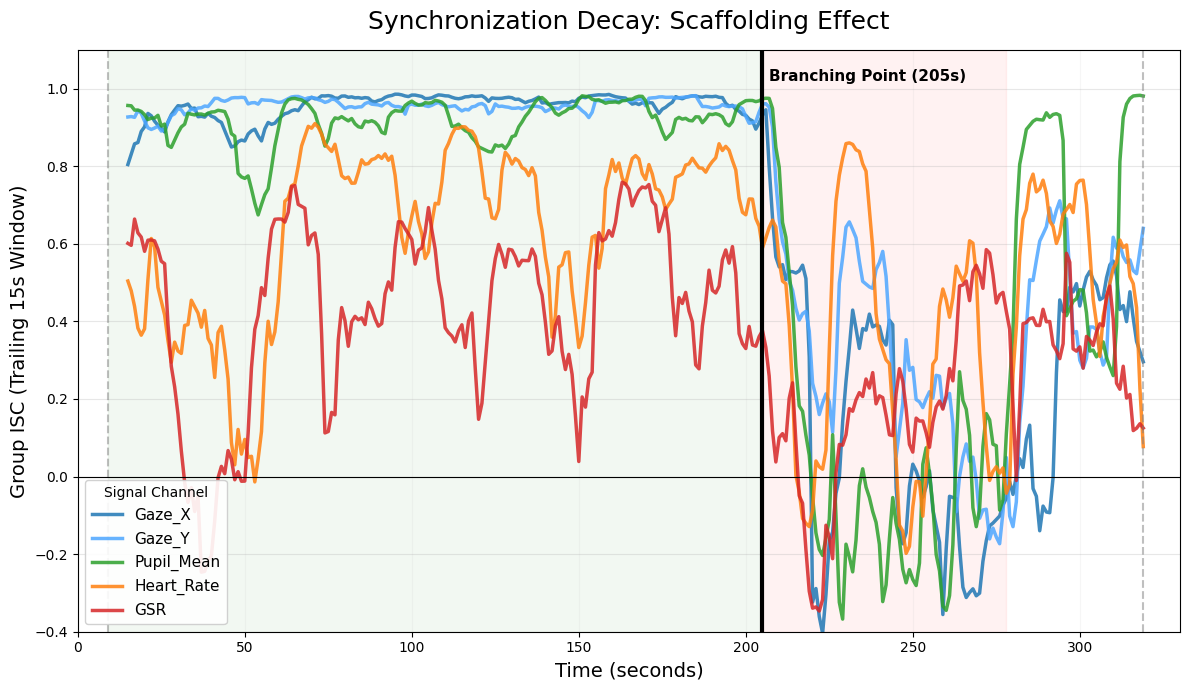

Unified plot saved to: /Users/schmaelz/Documents/01_GITHUB/nomcomm/GITHUB_PAPERS_WORKING/PC_HJ/data/04_analysis/segmented_causal/Unified_Decay_Scaffolding.png


In [19]:
# --- MAIN ANALYSIS ---
pc_subs  = utils.segment_isc_utils.get_subjects_by_condition(CONDITIONS_FILE, 'PC')
pcm_subs = utils.segment_isc_utils.get_subjects_by_condition(CONDITIONS_FILE, 'PCM')

all_results = []

print(f"Running Causal Sliding Window Analysis...")

for signal in signals_ordered:
    print(f"  Processing {signal}...")
    try:
        df_pc  = utils.segment_isc_utils.load_physio_data(DATA_DIR, pc_subs, signal_type=signal)
        df_pcm = utils.segment_isc_utils.load_physio_data(DATA_DIR, pcm_subs, signal_type=signal)
        
        # Run Calculation
        df_res = sliding_window_group_isc(df_pc, df_pcm, WIN_SIZE, STEP_SIZE, n_boot=200)
        
        # Tag and Store
        df_res['Signal'] = signal
        all_results.append(df_res)
        
    except Exception as e:
        print(f"    Error: {e}")

# 1. SAVE DATA
if all_results:
    final_df = pd.concat(all_results, ignore_index=True)
    csv_path = os.path.join(OUTPUT_DIR, "sliding_window_decay_results.csv")
    final_df.to_csv(csv_path, index=False)
    print(f"\nData saved to: {csv_path}")

    # 2. PLOTTING (Unified)
    print("Generating Unified Plot...")
    
    plt.figure(figsize=(12, 7))
    
    # Iterate in specific order to layer them correctly
    for signal in signals_ordered:
        subset = final_df[final_df['Signal'] == signal]
        
        # Plot only the Mean line (No Ribbons for clarity)
        # Using a slight transparency (alpha) to see overlaps
        plt.plot(subset['Time_Sec'], subset['Mean_r'], 
                 color=signal_colors[signal], 
                 label=signal, 
                 linewidth=2.5, 
                 alpha=0.85)

    # --- Draw Context (Lines & Shading) ---
    
    # Branching Point (205s)
    plt.axvline(205, color='black', linewidth=3, linestyle='-')
    plt.text(205 + 2, 1.02, "Branching Point (205s)", fontsize=11, fontweight='bold')

    # Shading regions
    plt.axvspan(9, 205, color='green', alpha=0.05, label='_nolegend_') # Common
    plt.axvspan(205, 278, color='red', alpha=0.05, label='_nolegend_') # Divergent
    
    # Other segment lines (optional, keep them thin)
    start_time = SEGMENTS['PC'][1][0]
    end_time = SEGMENTS['PC'][5][1]
    plt.axvline(start_time, color='gray', linestyle='--', alpha=0.5)
    plt.axvline(end_time, color='gray', linestyle='--', alpha=0.5)

    # --- Formatting ---
    plt.title("Synchronization Decay: Scaffolding Effect", fontsize=18, pad=15)
    plt.xlabel("Time (seconds)", fontsize=14)
    plt.ylabel(f"Group ISC (Trailing {WINDOW_SECONDS}s Window)", fontsize=14)
    
    plt.ylim(-0.4, 1.1)
    plt.xlim(0, 330)
    plt.axhline(0, color='black', linewidth=0.8)
    
    # Custom Grid
    plt.grid(axis='y', alpha=0.3)
    plt.grid(axis='x', alpha=0.1)

    # Legend
    plt.legend(title="Signal Channel", fontsize=11, loc='lower left', framealpha=0.9)
    
    plt.tight_layout()
    
    # Save Plot
    plot_path = os.path.join(OUTPUT_DIR, "Unified_Decay_Scaffolding.png")
    plt.savefig(plot_path, dpi=300)
    plt.show()
    print(f"Unified plot saved to: {plot_path}")

else:
    print("No results generated.")

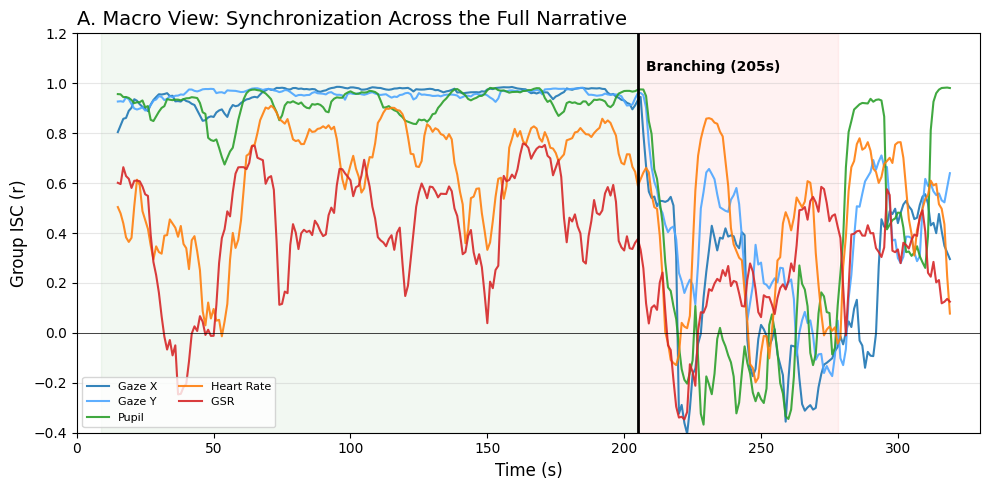

Saved Macro Plot to /Users/schmaelz/Documents/01_GITHUB/nomcomm/GITHUB_PAPERS_WORKING/PC_HJ/scripts/../data/04_analysis/segmented_causal/Plot_A_Macro_View.png


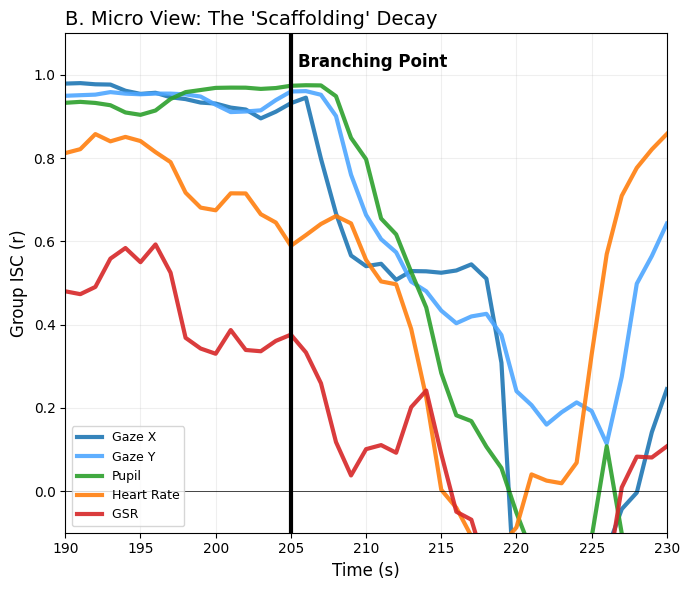

Saved Micro Plot to /Users/schmaelz/Documents/01_GITHUB/nomcomm/GITHUB_PAPERS_WORKING/PC_HJ/scripts/../data/04_analysis/segmented_causal/Plot_B_Micro_Fan.png


In [24]:
import pandas as pd
import matplotlib.pyplot as plt
import os
import numpy as np

# --- CONFIG ---
# Paths
current_dir = os.getcwd()
# Ensure this matches where you saved the CSV in the previous step
csv_path = os.path.join(current_dir, "../data/04_analysis/segmented_causal/sliding_window_decay_results.csv")
output_dir = os.path.join(current_dir, "../data/04_analysis/segmented_causal")

if not os.path.exists(csv_path):
    raise FileNotFoundError(f"Could not find results file at: {csv_path}\nPlease run the analysis step first.")

# Aesthetics
signals_ordered = ['Gaze_X', 'Gaze_Y', 'Pupil_Mean', 'Heart_Rate', 'GSR']

signal_colors = {
    'Gaze_X': '#1f77b4',      # Dark Blue
    'Gaze_Y': '#4da6ff',      # Light Blue
    'Pupil_Mean': '#2ca02c',  # Green
    'Heart_Rate': '#ff7f0e',  # Orange
    'GSR': '#d62728'          # Red
}

signal_labels = {
    'Gaze_X': 'Gaze X',
    'Gaze_Y': 'Gaze Y',
    'Pupil_Mean': 'Pupil',
    'Heart_Rate': 'Heart Rate',
    'GSR': 'GSR '
}

# Branching Point
BRANCH_TIME = 205

# --- LOAD DATA ---
df = pd.read_csv(csv_path)

# --- PLOT 1: THE MACRO VIEW (Whole Movie) ---
def plot_macro_view():
    plt.figure(figsize=(10, 5))
    
    # Plot Lines
    for sig in signals_ordered:
        subset = df[df['Signal'] == sig]
        plt.plot(subset['Time_Sec'], subset['Mean_r'], 
                 color=signal_colors[sig], label=signal_labels[sig], 
                 linewidth=1.5, alpha=0.9)

    # Branch Line
    plt.axvline(BRANCH_TIME, color='black', linewidth=2, linestyle='-')
    plt.text(BRANCH_TIME + 3, 1.05, "Branching (205s)", fontsize=10, fontweight='bold')

    # Shading
    plt.axvspan(9, BRANCH_TIME, color='green', alpha=0.05)
    plt.axvspan(BRANCH_TIME, 278, color='red', alpha=0.05)
    
    # Formatting
    plt.title("A. Macro View: Synchronization Across the Full Narrative", fontsize=14, loc='left')
    plt.xlabel("Time (s)", fontsize=12)
    plt.ylabel("Group ISC (r)", fontsize=12)
    plt.ylim(-0.4, 1.2)
    plt.xlim(0, 330)
    plt.axhline(0, color='black', linewidth=0.5)
    plt.grid(axis='y', alpha=0.3)
    
    # Legend (Compact)
    plt.legend(ncol=2, fontsize=8, loc='lower left')
    
    plt.tight_layout()
    save_path = os.path.join(output_dir, "Plot_A_Macro_View.png")
    plt.savefig(save_path, dpi=300)
    plt.show()
    print(f"Saved Macro Plot to {save_path}")

# --- PLOT 2: THE MICRO VIEW (The Scaffolding Fan) ---
def plot_micro_view():
    plt.figure(figsize=(7, 6)) # Portrait-ish for detail
    
    # Zoom Parameters
    x_start = 190
    x_end = 230
    
    # Plot Lines (Thicker for detail)
    for sig in signals_ordered:
        subset = df[df['Signal'] == sig]
        # Filter for optimization (optional, but good for cleanliness)
        subset = subset[(subset['Time_Sec'] >= x_start) & (subset['Time_Sec'] <= x_end)]
        
        # Dynamic alpha: Fade the noisy Gaze Y slightly if desired, or keep all bold
        alpha = 0.9
        lw = 3.0 # Thick lines!
        
        plt.plot(subset['Time_Sec'], subset['Mean_r'], 
                 color=signal_colors[sig], label=signal_labels[sig], 
                 linewidth=lw, alpha=alpha)

    # Branch Line
    plt.axvline(BRANCH_TIME, color='black', linewidth=3, linestyle='-')
    plt.text(BRANCH_TIME + 0.5, 1.02, "Branching Point", fontsize=12, fontweight='bold', ha='left')

    # Visual Guide for Window Delay
    # Since window is 15s, "Pure Scrambled" enters fully at 205+15=220.
    #window_end = BRANCH_TIME + 15
    #plt.axvline(window_end, color='gray', linewidth=1.5, linestyle=':')

    # Formatting
    plt.title("B. Micro View: The 'Scaffolding' Decay", fontsize=14, loc='left')
    plt.xlabel("Time (s)", fontsize=12)
    plt.ylabel("Group ISC (r)", fontsize=12)
    plt.ylim(-0.1, 1.1)
    plt.xlim(x_start, x_end)
    plt.axhline(0, color='black', linewidth=0.5)
    plt.grid(which='both', alpha=0.2)
    
    plt.legend(fontsize=9, loc='lower left')
    
    plt.tight_layout()
    save_path = os.path.join(output_dir, "Plot_B_Micro_Fan.png")
    plt.savefig(save_path, dpi=300)
    plt.show()
    print(f"Saved Micro Plot to {save_path}")

# --- EXECUTE ---
plot_macro_view()
plot_micro_view()

       Signal  Baseline_r  Time_to_Half_Drop  Persistence_Score  \
0      Gaze_X    0.944932               14.0           0.560345   
1      Gaze_Y    0.943701               10.0           0.612990   
2  Pupil_Mean    0.946161                9.0           0.533534   
3  Heart_Rate    0.752093                9.0           0.378616   
4         GSR    0.443410                3.0           0.104036   

   Memory_Residual  
0         0.073943  
1         0.139566  
2         0.060382  
3        -0.067599  
4        -0.164070  


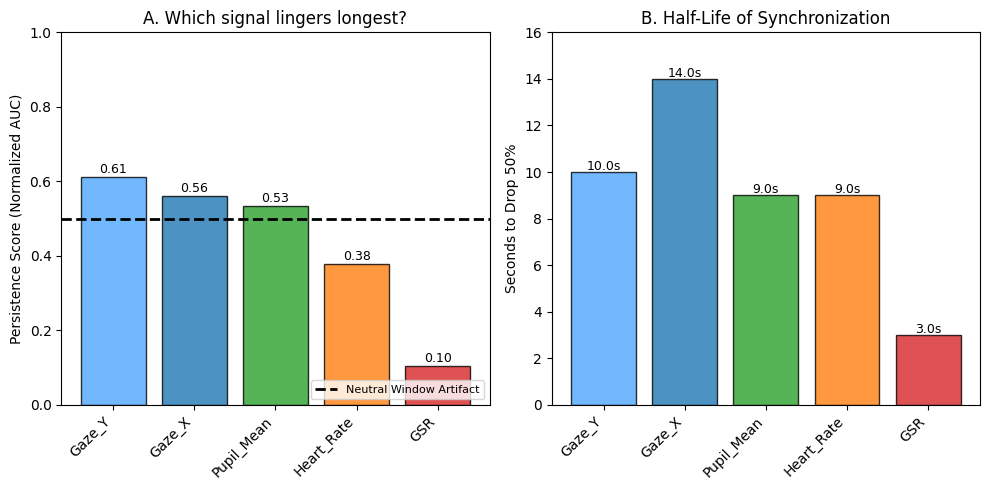

In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
from scipy.integrate import trapz

# --- CONFIG ---
current_dir = os.getcwd()
csv_path = os.path.join(current_dir, "../data/04_analysis/segmented_causal/sliding_window_decay_results.csv")
output_dir = os.path.join(current_dir, "../data/04_analysis/segmented_causal")

BRANCH_POINT = 205
WINDOW_SIZE = 15
TRANSITION_END = BRANCH_POINT + WINDOW_SIZE  # 220s

# Load Data
df = pd.read_csv(csv_path)

# --- QUANTIFICATION FUNCTION ---
def quantify_decay(df):
    stats = []
    
    signals = df['Signal'].unique()
    
    for sig in signals:
        subset = df[df['Signal'] == sig].sort_values('Time_Sec')
        
        # 1. Calculate Pre-Break Baseline (last 15s before break)
        baseline_mask = (subset['Time_Sec'] >= (BRANCH_POINT - 15)) & (subset['Time_Sec'] <= BRANCH_POINT)
        baseline_r = subset.loc[baseline_mask, 'Mean_r'].mean()
        
        # 2. Extract The "Decay Zone" (205s to 220s)
        decay_mask = (subset['Time_Sec'] > BRANCH_POINT) & (subset['Time_Sec'] <= TRANSITION_END)
        decay_data = subset.loc[decay_mask]
        
        if decay_data.empty: continue
            
        time_points = decay_data['Time_Sec'].values
        r_values = decay_data['Mean_r'].values
        
        # --- METRIC 1: Half-Life (Time to drop to 50% of baseline) ---
        # Find the first time point where r drops below baseline/2
        target_r = baseline_r * 0.5
        below_target = decay_data[decay_data['Mean_r'] < target_r]
        
        if not below_target.empty:
            t_half = below_target['Time_Sec'].iloc[0] - BRANCH_POINT
        else:
            t_half = WINDOW_SIZE # Saturation (didn't drop enough)
            
        # --- METRIC 2: Persistence (Area Under Curve) ---
        # We calculate the integral of the correlation during the transition
        auc = trapz(r_values, time_points)
        # Normalize: Divide by baseline * duration. 
        # 1.0 = Perfect Memory (stayed at baseline the whole time). 
        # 0.0 = Instant drop to 0. 
        # 0.5 = Linear drop (The "Null Hypothesis" of window artifact)
        max_possible_area = baseline_r * (time_points[-1] - time_points[0])
        norm_auc = auc / max_possible_area if max_possible_area > 0 else 0
        
        # --- METRIC 3: The "Memory Residual" ---
        # Compare actual curve to a theoretical linear drop (Window Artifact)
        # Linear drop equation: y = mx + c
        # Starts at baseline_r at t=0, goes to 0 at t=15
        relative_time = time_points - BRANCH_POINT
        theoretical_linear = baseline_r * (1 - (relative_time / WINDOW_SIZE))
        
        # Residual = Actual - Theoretical
        # Positive = Memory. Negative = Active Desynchronization.
        avg_residual = np.mean(r_values - theoretical_linear)

        stats.append({
            'Signal': sig,
            'Baseline_r': baseline_r,
            'Time_to_Half_Drop': t_half,
            'Persistence_Score': norm_auc, # > 0.5 means Memory
            'Memory_Residual': avg_residual # > 0 means Memory
        })
        
    return pd.DataFrame(stats)

# --- RUN AND PLOT ---
stats_df = quantify_decay(df)
print(stats_df)

# Save Stats
stats_df.to_csv(os.path.join(output_dir, "decay_quantification.csv"), index=False)

# --- PLOTTING THE METRICS ---
plt.figure(figsize=(10, 5))

# We define "Memory" as the threshold where the curve bulges outward vs inward.
# For Persistence Score (AUC), 0.5 is the linear drop (neutral).
# For Memory Residual, 0.0 is the linear drop (neutral).

# Plotting Persistence Score (AUC)
# Sort by Persistence to show the hierarchy
stats_df = stats_df.sort_values('Persistence_Score', ascending=False)

colors = {'Gaze_X': '#1f77b4', 'Gaze_Y': '#4da6ff', 'Pupil_Mean': '#2ca02c', 'Heart_Rate': '#ff7f0e', 'GSR': '#d62728'}
bar_colors = [colors[s] for s in stats_df['Signal']]

plt.subplot(1, 2, 1)
bars = plt.bar(stats_df['Signal'], stats_df['Persistence_Score'], color=bar_colors, edgecolor='black', alpha=0.8)
plt.axhline(0.5, color='black', linestyle='--', linewidth=2, label='Neutral Window Artifact')
plt.ylabel("Persistence Score (Normalized AUC)")
plt.title("A. Which signal lingers longest?", fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.ylim(0, 1.0)
plt.legend(loc='lower right', fontsize=8)

# Add text labels
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height + 0.01, f'{height:.2f}', ha='center', fontsize=9)


# Plotting Time to Half-Drop
plt.subplot(1, 2, 2)
bars2 = plt.bar(stats_df['Signal'], stats_df['Time_to_Half_Drop'], color=bar_colors, edgecolor='black', alpha=0.8)
plt.ylabel("Seconds to Drop 50%")
plt.title("B. Half-Life of Synchronization", fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.ylim(0, 16) # Max is 15s window

for bar in bars2:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height + 0.1, f'{height:.1f}s', ha='center', fontsize=9)

plt.tight_layout()
plt.savefig(os.path.join(output_dir, "Decay_Quantification_Barplots.png"), dpi=300)
plt.show()